# SI Fig. S2: barcode frequency stability across timepoints, Expt 2

One row per strain: barcode frequency at each of the six sequenced timepoints against
the next.  As in SI Fig. S1g, stability by the last two timepoints shows that lineages
have no appreciable fitness differences under selection, so the measured frequencies
reflect mutant numbers rather than subsequent competition.

Runtime: ~1 min.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import sys, time

import numpy as np
import matplotlib.pyplot as plt

from barfly import expt2                                    # noqa: E402
from barfly.plotting import use_paper_style                 # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
use_paper_style()
t_start = time.time()

params = expt2.load_params()
strains = params["strains"]
_, _, _, allcounts = expt2.load_counts(params)
PANEL = {"yKH88": "figS02b", "yFR1": "figS02c", "yFR2": "figS02d"}

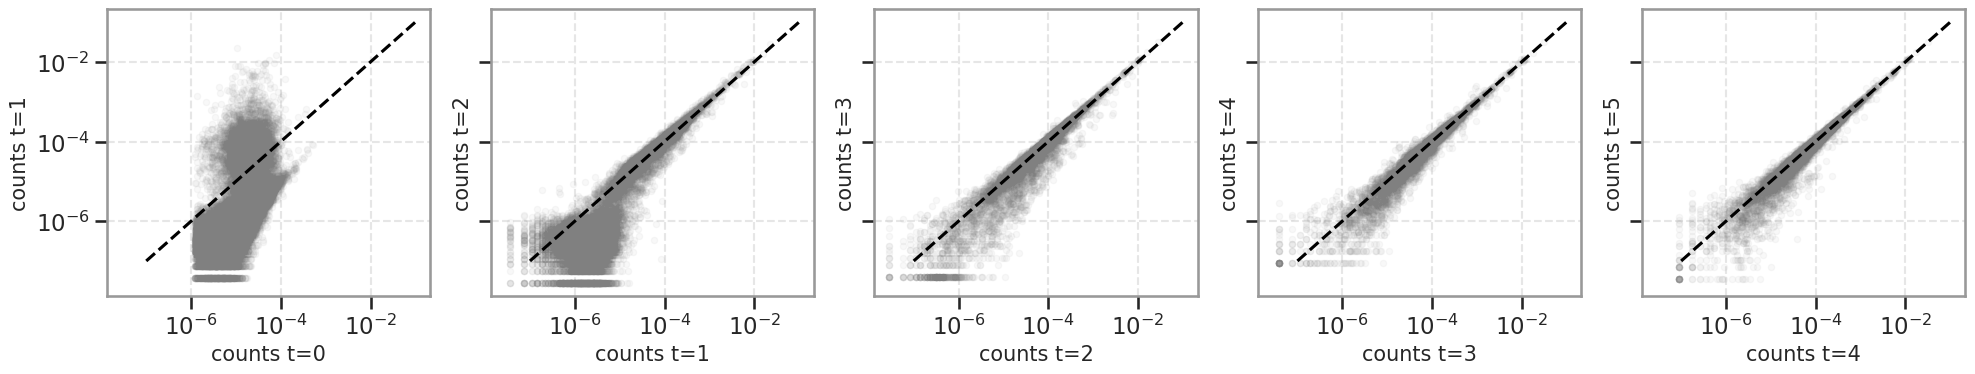

yKH88: 65789 barcodes, 6 timepoints


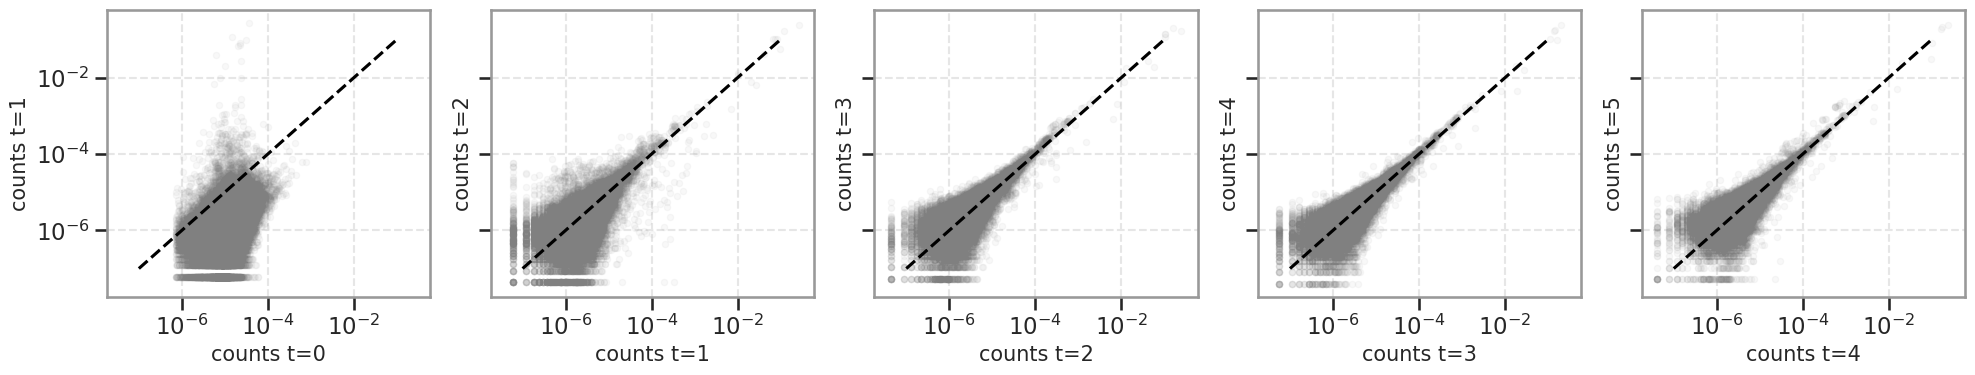

yFR1: 86832 barcodes, 6 timepoints


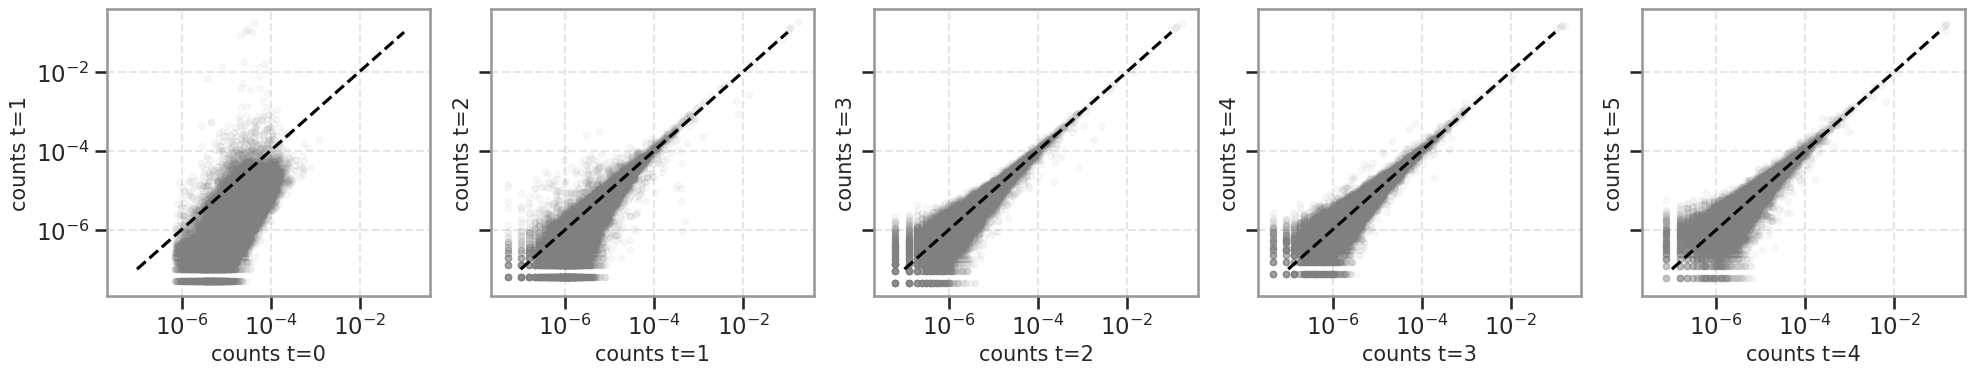

yFR2: 43528 barcodes, 6 timepoints
Done in 4.0s.


In [2]:
sys.path.insert(0, str(ROOT))
from barfly import expt2                                    # noqa: E402
from barfly.plotting import use_paper_style                 # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
use_paper_style()
t_start = time.time()

params = expt2.load_params()
strains = params["strains"]
_, _, _, allcounts = expt2.load_counts(params)
PANEL = {"yKH88": "figS02b", "yFR1": "figS02c", "yFR2": "figS02d"}

for strain in strains:
    tc = allcounts[f"{expt2.T0_SAMPLE[strain]}_f1r1"]["umiCounts"]
    bcds = np.array([b for b in tc if tc[b] > params["minreads"]])
    timecourse = expt2.TIMECOURSE[strain]
    count_matrix = np.zeros([len(timecourse), len(bcds)])
    for t, key in enumerate(timecourse):
        sample_counts = allcounts[f"{key}_f1r1"]["umiCounts"]
        count_matrix[t, :] = np.array([sample_counts.get(b, 0) for b in bcds])

    n_timepoints = count_matrix.shape[0]
    fig, axs = plt.subplots(1, n_timepoints - 1, sharex=True, sharey=True, figsize=(20, 4))
    for t in range(n_timepoints - 1):
        axs[t].plot(count_matrix[t, :] / np.sum(count_matrix[t, :]), count_matrix[t + 1, :] / np.sum(count_matrix[t + 1, :]),
                    ".", color="gray", rasterized=True, alpha=0.05)
        axs[t].plot([1e-7, 1e-1], [1e-7, 1e-1], "--k")
        axs[t].set_xscale("log"); axs[t].set_yscale("log")
        axs[t].set_xlabel(f"counts t={t}"); axs[t].set_ylabel(f"counts t={t+1}")
    plt.tight_layout()
    plt.savefig(OUT / f"{PANEL[strain]}_trajectories_{strain}.svg",
                bbox_inches="tight", dpi=300)
    plt.show()
    print(f"{strain}: {len(bcds)} barcodes, {n_timepoints} timepoints")

print(f"Done in {time.time()-t_start:.1f}s.")